# Gallstone data visualization with PySpark — Google Colab
This notebook supports the **Data Understanding** phase of CRISP-DM. Run the cells in order in a Colab CPU runtime. The dataset is read with Spark; validation, statistics, binning, grouped quartiles and correlations are calculated with Spark. Matplotlib renders the small summaries collected from Spark. No pandas conversion is used.

The raw dataset is fetched from this GitHub repository if it is not already available locally. Original ordinal/binary codes are retained. Source status `0` means gallstones present; this notebook maps that to modelling label `1`.

These whole-cohort plots are exploratory. They are not test performance, tuning evidence, clinical effects or an independently validated model. Training-only preparation and holdout evaluation remain in the Iteration 4 workflows.

In [6]:
!pwd

/content


## 1. Check the Colab runtime
Only missing Python packages are installed. An existing Java runtime is required. This cell does not install Java or mount Google Drive.

In [7]:
import sys, subprocess, shutil, importlib.util
from pathlib import Path
INSTALL_MISSING = True  # Set False to require a preconfigured runtime.
requirements = {'pyspark': 'pyspark>=3.5.3,<4.0', 'matplotlib': 'matplotlib>=3.7', 'numpy': 'numpy>=1.24'}
missing = [requirement for module, requirement in requirements.items()
           if importlib.util.find_spec(module) is None]
if missing:
    if not INSTALL_MISSING:
        raise RuntimeError(f'Missing packages: {missing}. Enable INSTALL_MISSING in Colab.')
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', *missing])
java = shutil.which('java')
if java is None:
    raise RuntimeError('Java is missing. Use a runtime with Java available before starting Spark.')
java_check = subprocess.run([java, '-version'], capture_output=True, text=True)
if java_check.returncode:
    raise RuntimeError('Java could not start: ' + java_check.stderr)
print(java_check.stderr or java_check.stdout)


openjdk version "21.0.12.1" 2026-08-18
OpenJDK Runtime Environment (build 21.0.12.1+1-1-24.04.4-Ubuntu)
OpenJDK 64-Bit Server VM (build 21.0.12.1+1-1-24.04.4-Ubuntu, mixed mode, sharing)



In [8]:
import json
import numpy as np
import matplotlib.pyplot as plt
import pyspark
from pyspark.sql import SparkSession, functions as F
from pyspark.ml.feature import VectorAssembler
from pyspark.ml.stat import Correlation
spark = (SparkSession.builder.master('local[*]')
         .appName('INFOSYS722-PySpark-Visualization')
         .config('spark.sql.shuffle.partitions', '4')
         .getOrCreate())
spark.sparkContext.setLogLevel('WARN')
OUTPUT_DIR = Path.cwd() / 'pyspark_visualizations'
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
COLORS = {'Absent': '#4477AA', 'Present': '#EE7733'}
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False})
def save_figure(fig, name):
    fig.tight_layout()
    for suffix in ('png', 'pdf'):
        fig.savefig(OUTPUT_DIR / f'{name}.{suffix}', bbox_inches='tight', dpi=180)
    plt.show()
print('Spark:', pyspark.__version__, '| Figures:', OUTPUT_DIR)


Spark: 4.0.4 | Figures: /content/pyspark_visualizations


## 2. Load and validate the data with Spark
Set `DATA_PATH` to your own raw CSV if required. The default download uses the repository dataset, without Google Drive or a ZIP.

In [9]:
from urllib.request import urlretrieve
DATA_PATH = next((p for p in (
    Path.cwd() / 'iteration4_BDAS/data/raw/dataset_gallstone',
    Path.cwd().parent / 'iteration4_BDAS/data/raw/dataset_gallstone',
    Path('/content/INFOSYS722_BDAS/iteration4_BDAS/data/raw/dataset_gallstone'),
    Path('/content/dataset_gallstone'),
) if p.is_file()), None)
if DATA_PATH is None:
    DATA_PATH = Path.cwd() / 'dataset_gallstone'
    urlretrieve('https://raw.githubusercontent.com/QuyDuong106/INFOSYS722_BDAS/main/iteration4_BDAS/data/raw/dataset_gallstone', DATA_PATH)
raw = spark.read.option('header', True).option('inferSchema', True).csv(str(DATA_PATH.resolve()))
excluded = [c for c in raw.columns if c.startswith('_c') or c.startswith('Unnamed:') or c == 'record_id']
raw = raw.drop(*excluded)
if 'gallstone_status' not in raw.columns:
    raise ValueError('Expected the raw dataset with gallstone_status.')
source_status = F.col('gallstone_status').cast('double')
if raw.filter(source_status.isNull() | ~source_status.isin(0.0, 1.0)).limit(1).count():
    raise ValueError('Source status must contain only 0 (present) and 1 (absent).')
FEATURES = [c for c in raw.columns if c != 'gallstone_status']
CODED = {'gender', 'comorbidity', 'cad', 'hypothyroidism', 'hyperlipidemia', 'dm', 'hfa'}
CATEGORICAL = [c for c in FEATURES if c in CODED]
CONTINUOUS = [c for c in FEATURES if c not in CODED]
for column in FEATURES:
    if raw.filter(F.col(column).isNotNull() & F.col(column).cast('double').isNull()).limit(1).count():
        raise ValueError(f'Non-numeric value in {column}; review the source file.')
df = raw.select(*[F.col(c).cast('double').alias(c) for c in raw.columns])
for c in FEATURES:
    df = df.withColumn(c, F.when(F.isnan(c) | (F.abs(F.col(c)) == float('inf')), None).otherwise(F.col(c)))
df = (df.withColumn('label', (1 - F.col('gallstone_status')).cast('int'))
      .withColumn('status', F.when(F.col('label') == 1, 'Present').otherwise('Absent'))).cache()
N = df.count()
if N == 0:
    raise ValueError('Dataset is empty.')
if df.select('label').distinct().count() != 2:
    raise ValueError('Both outcome classes are required for the comparison plots.')
duplicates = N - df.select(*raw.columns).dropDuplicates().count()
print(f'{N} records | {len(FEATURES)} predictors | {duplicates} duplicate records')
print('Excluded exported index/identifier fields:', excluded)
print('Categorical codes:', CATEGORICAL)
df.groupBy('status').count().orderBy('status').show()
df.select('age', 'bmi', 'glucose', 'crp', 'status').show(5)


319 records | 38 predictors | 0 duplicate records
Excluded exported index/identifier fields: ['_c0']
Categorical codes: ['gender', 'comorbidity', 'cad', 'hypothyroidism', 'hyperlipidemia', 'dm', 'hfa']
+-------+-----+
| status|count|
+-------+-----+
| Absent|  158|
|Present|  161|
+-------+-----+

+----+----+-------+---+-------+
| age| bmi|glucose|crp| status|
+----+----+-------+---+-------+
|50.0|27.1|  102.0|0.0|Present|
|47.0|30.5|   94.0|0.0|Present|
|61.0|31.2|  103.0|0.0|Present|
|41.0|24.0|   69.0|0.0|Present|
|42.0|28.3|  109.0|0.0|Present|
+----+----+-------+---+-------+
only showing top 5 rows


## 3. Outcome distribution
Counts and percentages are computed from Spark groups. The colours consistently represent absence and presence throughout the notebook.

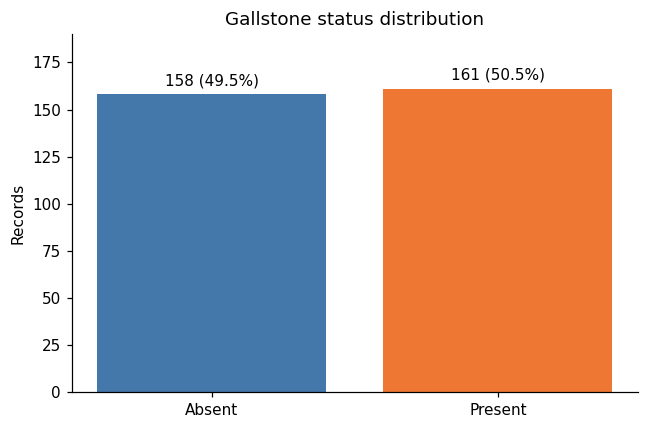

In [10]:
outcome_counts = df.groupBy('status').count().orderBy('status').collect()
fig, ax = plt.subplots(figsize=(6, 4))
bars = ax.bar([r.status for r in outcome_counts], [r['count'] for r in outcome_counts],
              color=[COLORS[r.status] for r in outcome_counts])
for bar, row in zip(bars, outcome_counts):
    ax.annotate(f"{row['count']} ({100*row['count']/N:.1f}%)",
                (bar.get_x() + bar.get_width()/2, bar.get_height()),
                ha='center', va='bottom', xytext=(0, 4), textcoords='offset points')
ax.set(title='Gallstone status distribution', ylabel='Records', ylim=(0, max(r['count'] for r in outcome_counts)*1.18))
save_figure(fig, '01_outcome_distribution')


## 4. Data-quality overview
Missing-value counts cover predictors only. Nonfinite numeric entries were mapped to missing values during validation; no imputation or feature selection is performed for these plots.

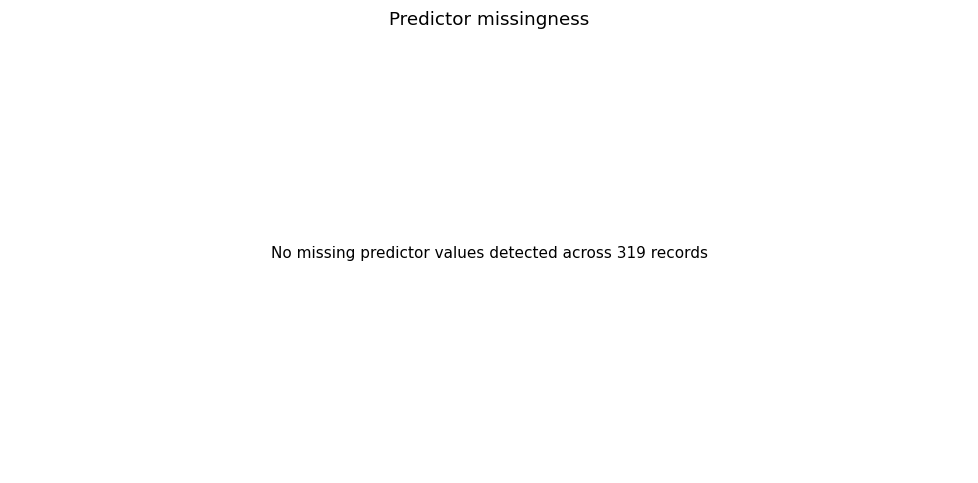

784

In [11]:
missing_row = df.agg(*[F.sum(F.when(F.col(c).isNull(), 1).otherwise(0)).alias(c) for c in FEATURES]).first()
missing = sorted([(c, int(missing_row[c] or 0)) for c in FEATURES], key=lambda x: x[1], reverse=True)
fig, ax = plt.subplots(figsize=(9, 4.5))
nonzero = [(c, count) for c, count in missing if count > 0]
if nonzero:
    ax.barh([c for c, _ in nonzero][::-1], [100*count/N for _, count in nonzero][::-1], color='#4477AA')
    ax.set(xlabel='Missing values (%)', title='Predictor missingness')
else:
    ax.text(.5, .5, f'No missing predictor values detected across {N} records',
            ha='center', va='center', transform=ax.transAxes)
    ax.set_axis_off()
    ax.set_title('Predictor missingness')
save_figure(fig, '02_missingness')
quality = {'rows': N, 'predictors': len(FEATURES), 'duplicate_records': duplicates,
           'missing_counts': dict(missing), 'source_label_mapping': {'0': 'Present', '1': 'Absent'}}
(OUTPUT_DIR / 'data_quality.json').write_text(json.dumps(quality, indent=2))


## 5. Continuous-variable distributions
Spark assigns observations to equal-width bins and counts them. Only bin counts are collected; the full patient table is not converted to pandas. Plot labels use the source field names.

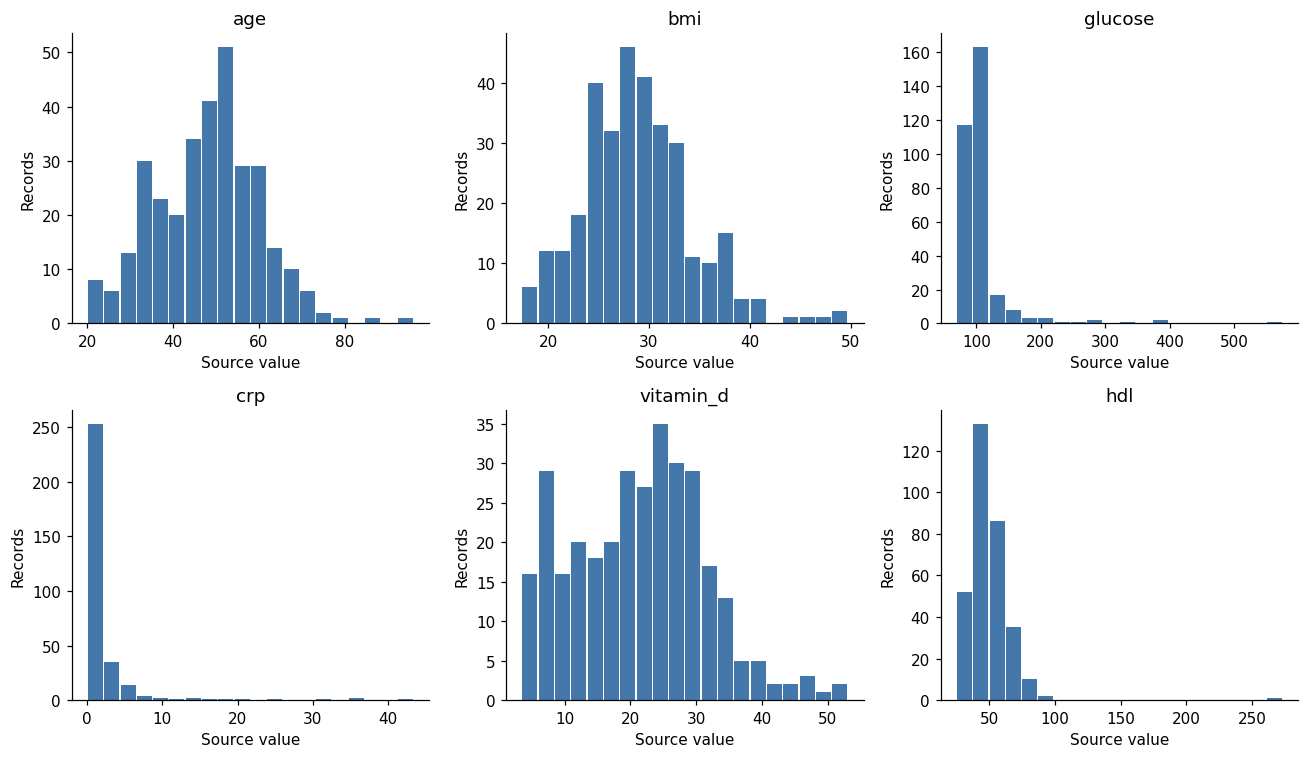

In [12]:
PLOT_FEATURES = [c for c in ('age', 'bmi', 'glucose', 'crp', 'vitamin_d', 'hdl') if c in CONTINUOUS]
def histogram_summary(frame, column, bins=20):
    limits = frame.agg(F.min(column).alias('lo'), F.max(column).alias('hi')).first()
    if limits.lo is None:
        return None
    if limits.lo == limits.hi:
        return np.array([limits.lo]), np.array([frame.filter(F.col(column).isNotNull()).count()]), 1.0
    width = (limits.hi - limits.lo)/bins
    bucket = F.least(F.floor((F.col(column)-limits.lo)/width), F.lit(bins-1)).cast('int')
    rows = frame.filter(F.col(column).isNotNull()).groupBy(bucket.alias('bin')).count().collect()
    counts = np.zeros(bins)
    for row in rows:
        counts[row.bin] = row['count']
    centres = limits.lo + (np.arange(bins)+.5)*width
    return centres, counts, width
fig, axes = plt.subplots(2, 3, figsize=(12, 7))
for ax, column in zip(axes.flat, PLOT_FEATURES):
    hist = histogram_summary(df, column)
    if hist is None:
        ax.text(.5, .5, 'No observed values', ha='center', transform=ax.transAxes)
    else:
        centres, counts, width = hist
        ax.bar(centres, counts, width=width*.92, color='#4477AA')
    ax.set(title=column, xlabel='Source value', ylabel='Records')
for ax in list(axes.flat)[len(PLOT_FEATURES):]:
    ax.set_axis_off()
save_figure(fig, '03_continuous_distributions')


## 6. Continuous variables by outcome
Spark calculates approximate quartiles separately for each outcome. Boxes show the interquartile range and median; whiskers show the observed minimum and maximum, **not** Tukey 1.5-IQR fences. These comparisons are descriptive, without causal or significance claims.

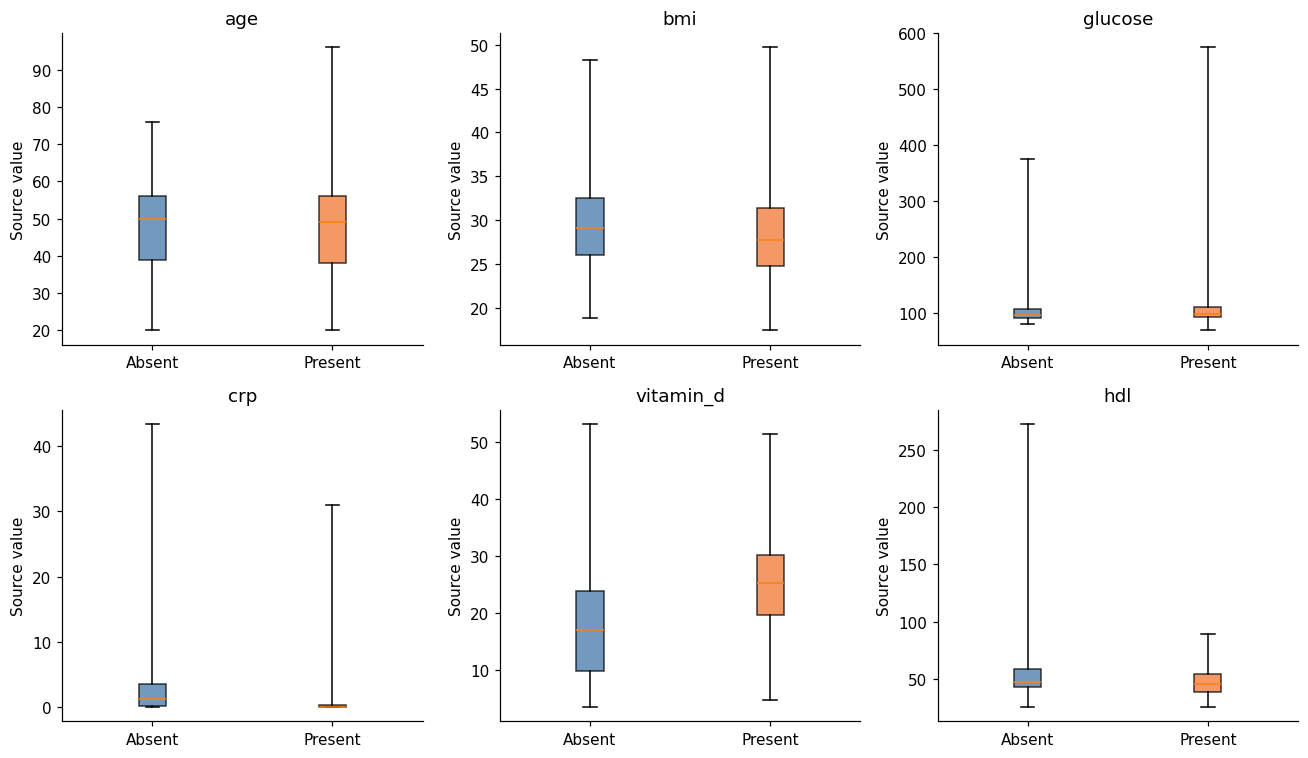

In [13]:
fig, axes = plt.subplots(2, 3, figsize=(12, 7))
for ax, column in zip(axes.flat, PLOT_FEATURES):
    rows = (df.filter(F.col(column).isNotNull()).groupBy('status')
            .agg(F.percentile_approx(column, [.25, .5, .75], 10000).alias('q'),
                 F.min(column).alias('lo'), F.max(column).alias('hi'))
            .orderBy('status').collect())
    stats = [dict(label=r.status, q1=r.q[0], med=r.q[1], q3=r.q[2],
                  whislo=r.lo, whishi=r.hi) for r in rows]
    if stats:
        artists = ax.bxp(stats, showfliers=False, patch_artist=True)
        for patch, row in zip(artists['boxes'], rows):
            patch.set_facecolor(COLORS[row.status]); patch.set_alpha(.75)
    ax.set(title=column, ylabel='Source value')
for ax in list(axes.flat)[len(PLOT_FEATURES):]:
    ax.set_axis_off()
save_figure(fig, '04_distributions_by_outcome')


## 7. Coded categorical predictors
Bars show the percentage of each outcome group with a given original category code. Missing values form a separate category. Codes are shown as supplied rather than assigned unverified clinical labels.

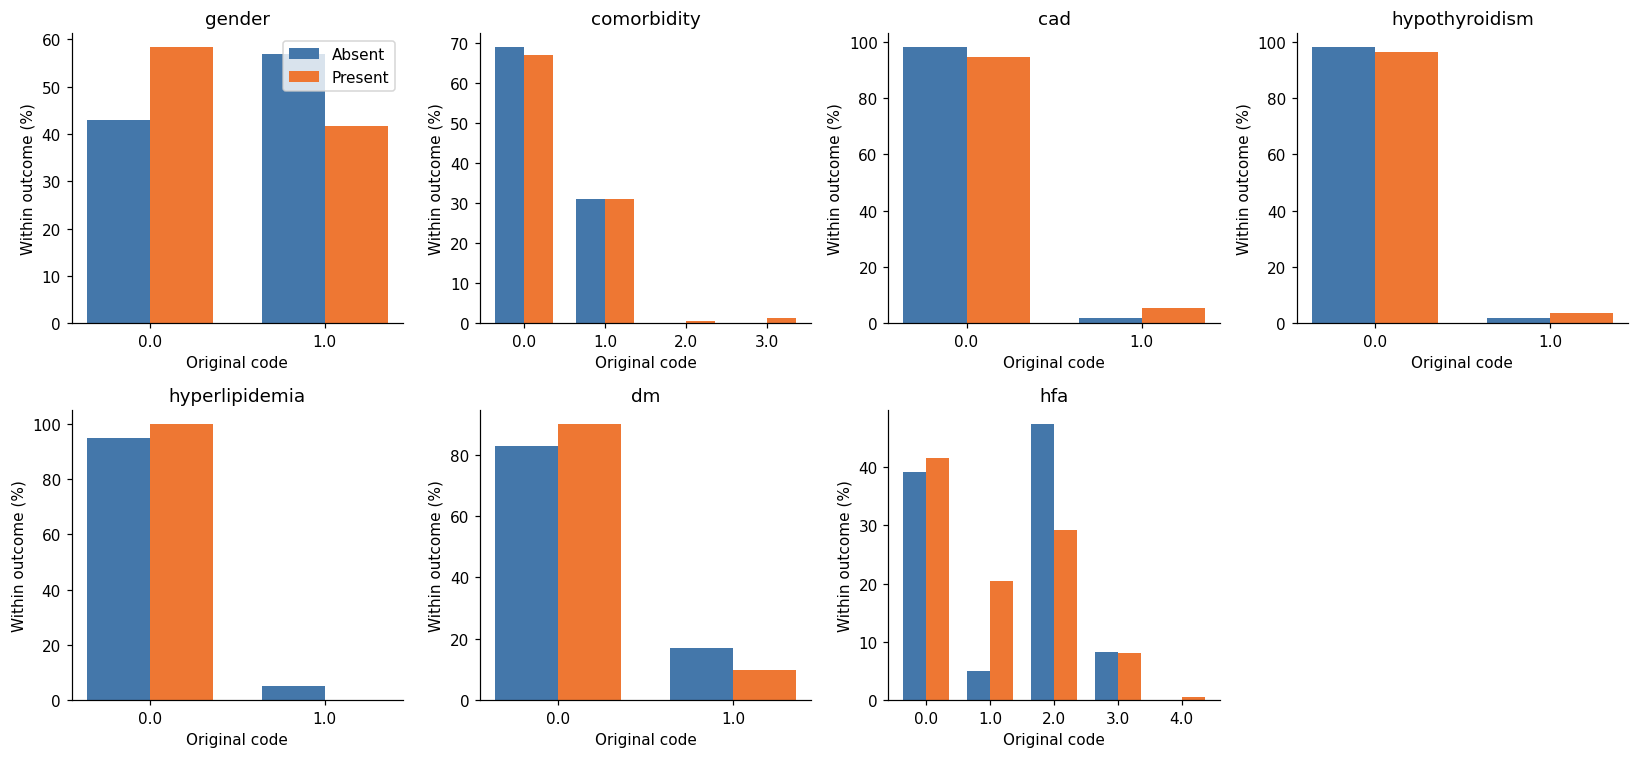

In [14]:
fig, axes = plt.subplots(2, 4, figsize=(15, 7))
denominators = {r.status: r['count'] for r in outcome_counts}
for ax, column in zip(axes.flat, CATEGORICAL):
    category = F.when(F.col(column).isNull(), 'Missing').otherwise(F.col(column).cast('string'))
    grouped = df.groupBy(category.alias('code'), 'status').count().collect()
    codes = sorted({r.code for r in grouped}, key=lambda x: (x == 'Missing', float(x) if x != 'Missing' else 0))
    lookup = {(r.code, r.status): r['count'] for r in grouped}
    x = np.arange(len(codes)); width = .36
    for i, status in enumerate(('Absent', 'Present')):
        values = [100*lookup.get((c, status), 0)/denominators[status] for c in codes]
        ax.bar(x+(i-.5)*width, values, width=width, label=status, color=COLORS[status])
    ax.set(xticks=x, xticklabels=codes, title=column, xlabel='Original code', ylabel='Within outcome (%)')
axes.flat[0].legend()
for ax in list(axes.flat)[len(CATEGORICAL):]:
    ax.set_axis_off()
save_figure(fig, '05_categorical_patterns')


## 8. Pearson correlation heatmap
Spark ML computes the matrix using complete records for continuous predictors. Constant fields are excluded. Correlation measures linear association, and cannot establish causality or feature importance. The binary target and coded categories are excluded.

Complete records for correlation: 319 / 319


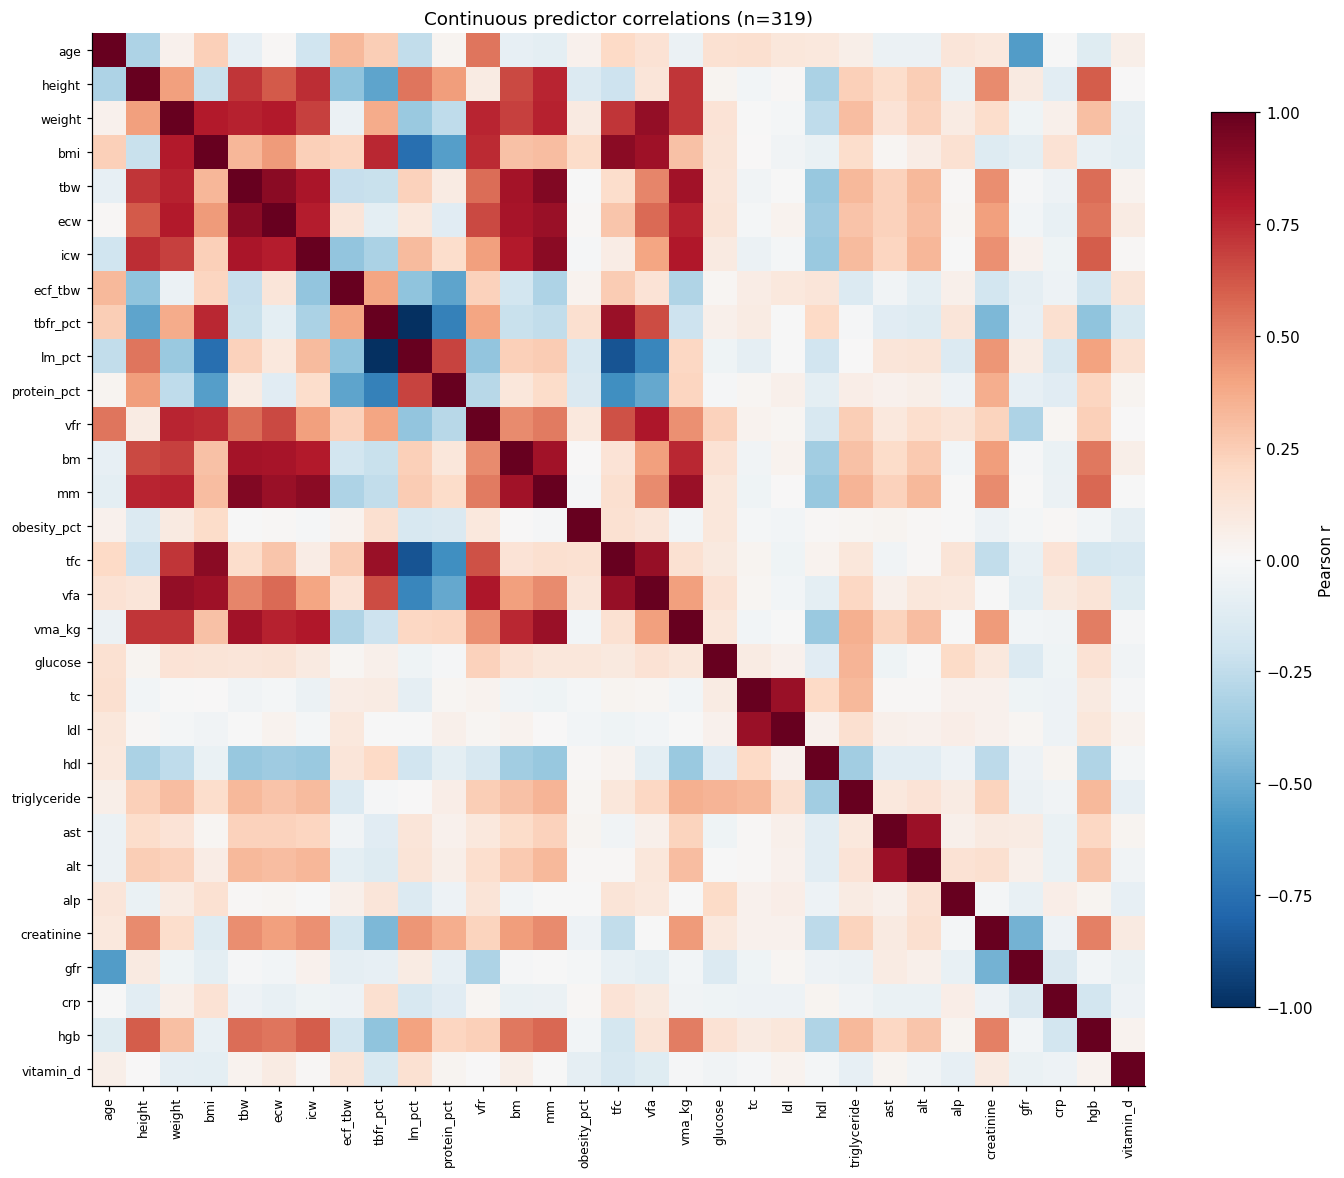

In [15]:
deviations = df.agg(*[F.stddev_samp(c).alias(c) for c in CONTINUOUS]).first()
CORRELATION_FEATURES = [c for c in CONTINUOUS if deviations[c] is not None and deviations[c] > 0]
complete = df.select(*CORRELATION_FEATURES).dropna()
complete_n = complete.count()
print('Complete records for correlation:', complete_n, '/', N)
if len(CORRELATION_FEATURES) >= 2 and complete_n >= 2:
    assembled = VectorAssembler(inputCols=CORRELATION_FEATURES, outputCol='features').transform(complete)
    matrix = Correlation.corr(assembled, 'features', 'pearson').first()[0].toArray()
    fig, ax = plt.subplots(figsize=(13, 11))
    image = ax.imshow(np.ma.masked_invalid(matrix), cmap='RdBu_r', vmin=-1, vmax=1)
    positions = np.arange(len(CORRELATION_FEATURES))
    ax.set(xticks=positions, yticks=positions, xticklabels=CORRELATION_FEATURES,
           yticklabels=CORRELATION_FEATURES, title=f'Continuous predictor correlations (n={complete_n})')
    plt.setp(ax.get_xticklabels(), rotation=90, fontsize=8)
    plt.setp(ax.get_yticklabels(), fontsize=8)
    fig.colorbar(image, ax=ax, shrink=.8, label='Pearson r')
    save_figure(fig, '06_correlation_heatmap')
    np.savetxt(OUTPUT_DIR/'correlation_matrix.csv', matrix, delimiter=',',
               header=','.join(CORRELATION_FEATURES), comments='')
else:
    print('Insufficient complete records or varying continuous fields for correlation.')


## 9. BMI and glucose relationship
Spark groups BMI and glucose into a 12×12 grid. Colour is gallstone prevalence within each bin; marker area represents the bin count. Bins with fewer than three observations are omitted to avoid interpreting unstable small-cell rates. This is an exploratory relationship, not a clinical risk model.

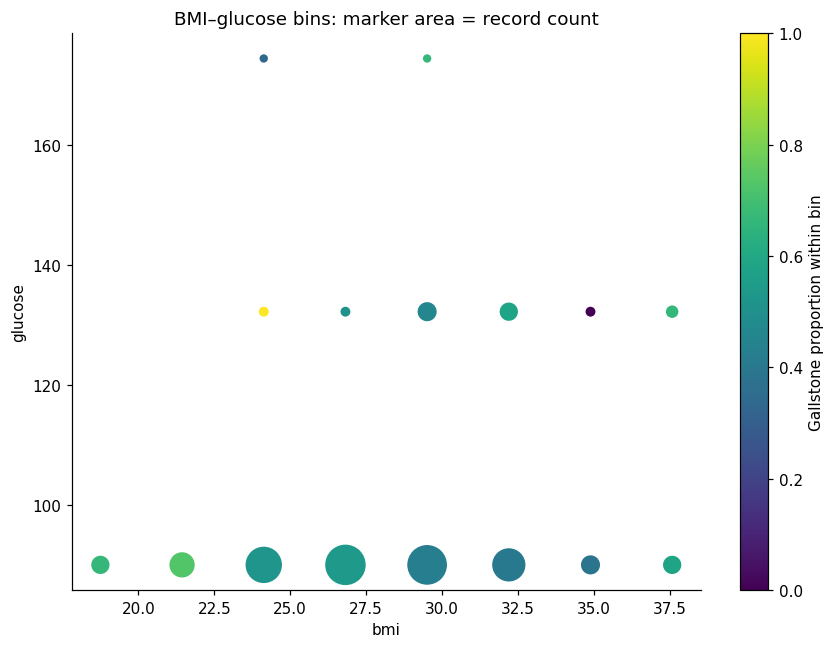

In [16]:
x_col, y_col = 'bmi', 'glucose'
base = df.filter(F.col(x_col).isNotNull() & F.col(y_col).isNotNull())
limits = base.agg(F.min(x_col).alias('xmin'), F.max(x_col).alias('xmax'),
                  F.min(y_col).alias('ymin'), F.max(y_col).alias('ymax')).first()
BINS = 12
if limits.xmin is not None and limits.xmax > limits.xmin and limits.ymax > limits.ymin:
    dx = (limits.xmax-limits.xmin)/BINS; dy = (limits.ymax-limits.ymin)/BINS
    xbin = F.least(F.floor((F.col(x_col)-limits.xmin)/dx), F.lit(BINS-1)).cast('int')
    ybin = F.least(F.floor((F.col(y_col)-limits.ymin)/dy), F.lit(BINS-1)).cast('int')
    grid = (base.groupBy(xbin.alias('xbin'), ybin.alias('ybin'))
            .agg(F.count('*').alias('n'), F.mean('label').alias('rate')))
    rows = grid.filter(F.col('n') >= 3).collect()
    fig, ax = plt.subplots(figsize=(8, 6))
    if rows:
        points = ax.scatter([limits.xmin+(r.xbin+.5)*dx for r in rows],
                            [limits.ymin+(r.ybin+.5)*dy for r in rows],
                            c=[r.rate for r in rows], s=[r.n*14 for r in rows],
                            cmap='viridis', vmin=0, vmax=1, edgecolors='white')
        fig.colorbar(points, ax=ax, label='Gallstone proportion within bin')
    else:
        ax.text(.5, .5, 'No bins contain at least three records', ha='center', transform=ax.transAxes)
    ax.set(xlabel=x_col, ylabel=y_col, title='BMI–glucose bins: marker area = record count')
    save_figure(fig, '07_bmi_glucose_relationship')
    grid.orderBy('xbin', 'ybin').coalesce(1).write.mode('overwrite').option('header', True).csv(str(OUTPUT_DIR/'bmi_glucose_bins'))
else:
    print('Observed BMI/glucose ranges do not support two-dimensional bins.')


## 10. Save your outputs
Figures are saved as PNG and PDF in `pyspark_visualizations/`, along with the data-quality JSON, correlation matrix and binned summary. Download individual figures from Colab’s Files sidebar before ending the session. The optional cell below downloads the correlation figure. No ZIP is required.

In [17]:
print('Output directory:', OUTPUT_DIR.resolve())
for path in sorted(OUTPUT_DIR.iterdir()):
    print(path.name)
# Optional individual download in Colab:
# from google.colab import files
# files.download(str(OUTPUT_DIR / '06_correlation_heatmap.png'))


Output directory: /content/pyspark_visualizations
01_outcome_distribution.pdf
01_outcome_distribution.png
02_missingness.pdf
02_missingness.png
03_continuous_distributions.pdf
03_continuous_distributions.png
04_distributions_by_outcome.pdf
04_distributions_by_outcome.png
05_categorical_patterns.pdf
05_categorical_patterns.png
06_correlation_heatmap.pdf
06_correlation_heatmap.png
07_bmi_glucose_relationship.pdf
07_bmi_glucose_relationship.png
bmi_glucose_bins
correlation_matrix.csv
data_quality.json


## Interpretation and next steps
Describe what the plots show, retain source coding and note overlap/correlation between body-composition measures. Apparent outcome separation is a hypothesis for training-only modelling, not a reason to inspect held-out labels during feature selection. Return to Iteration 4 for its fold-safe preparation, tuning and evaluation. Native Spark figures and model metrics must be labelled as separate evidence from the main five-family Optuna results.